# 03 · Model development: can a model tell a child's brain from an adult's? (H1, H3)

**Approach**
- **Features:** the 741 connections per person.
- **Model:** logistic regression with feature scaling. It is simple and linear, and its weights map back onto real connections. `class_weight="balanced"` because there are ~3 children per adult.
- **Metric:** **balanced accuracy** (mean of the child and adult hit rates). Plain accuracy would be ~73% just by always saying "child".
- **Validation:** stratified 5-fold cross-validation, repeated 10 times with different splits. The model is always tested on people it never saw, and everything that learns from data (including the tangent connectivity reference) is fitted on training people only.

We compare three connectivity measures against two baselines, then check whether head motion explains the result (H3).

*Requires the outputs of notebook 01 in `data/`.*

In [1]:
# --- Setup -------------------------------------------------------------------
# Running on Google Colab? First run, in a new cell:
#   !git clone https://github.com/Leena2403/Brain_Network_Development_fMRI.git
#   %cd Brain_Network_Development_fMRI/notebooks
#   !pip install -q -r ../requirements.txt
import sys
sys.path.append("..")   # so we can import our own code from ../src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from nilearn import plotting

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"child": "#E69F00", "adult": "#0072B2"}   # colour-blind-safe orange / blue
DATA_DIR = "../data"                # intermediate files (not committed to git)
FIG_DIR = "../results/figures"      # figures used in the README

def save(name):
    """Save the current figure for the README."""
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

In [2]:
from src.feature_extraction import load_atlas

# Outputs of notebook 01
pheno = pd.read_csv(f"{DATA_DIR}/participants_clean.csv")
saved = np.load(f"{DATA_DIR}/time_series_msdl.npz", allow_pickle=True)
time_series = list(saved["time_series"])
assert list(saved["ids"]) == list(pheno["participant_id"]), "Rerun notebook 01"

atlas_maps, labels, networks, coords = load_atlas()
is_child = (pheno["Child_Adult"] == "child").values
y = (~is_child).astype(int)   # 0 = child, 1 = adult

print(f"{len(time_series)} participants ({is_child.sum()} children, {(~is_child).sum()} adults), "
      f"{time_series[0].shape[0]} time points x {time_series[0].shape[1]} regions each")

120 participants (88 children, 32 adults), 168 time points x 39 regions each


## 1. Compare connectivity measures

| Measure | What it captures |
|---|---|
| **correlation** | Do two regions rise and fall together? (direct + indirect links) |
| **partial correlation** | Link between two regions after removing all the others (direct links only, noisier) |
| **tangent** | Each person's deviation from the group-average pattern (Varoquaux et al., 2010; often best for classification) |

In [3]:
from src.evaluation import cross_validate

cv_results = {}
for kind in ["correlation", "partial correlation", "tangent"]:
    cv_results[kind] = cross_validate(time_series, y, kind=kind)
    s = cv_results[kind]["scores"]
    print(f"{kind:20s} balanced accuracy = {s.mean():.3f} ± {s.std():.3f}")

correlation          balanced accuracy = 0.945 ± 0.055


partial correlation  balanced accuracy = 0.875 ± 0.082


tangent              balanced accuracy = 0.937 ± 0.051


## 2. Baselines
- **Chance:** always predicts the larger group → 0.50 balanced accuracy.
- **Motion only:** a model that sees *only* each person's mean FD. If this were close to the connectivity models, they might just be detecting movement.

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.evaluation import baseline_scores

X_fd = pheno[["mean_fd"]].values
scores = {kind: r["scores"] for kind, r in cv_results.items()}
scores["chance"] = baseline_scores(X_fd, y, DummyClassifier(strategy="most_frequent"))
scores["motion only"] = baseline_scores(
    X_fd, y, make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")))

for k in ["chance", "motion only"]:
    print(f"{k:20s} balanced accuracy = {scores[k].mean():.3f} ± {scores[k].std():.3f}")

chance               balanced accuracy = 0.500 ± 0.000
motion only          balanced accuracy = 0.635 ± 0.100


## 3. Is it just motion? (H3)

Two checks:
1. **Remove motion from the features.** Inside each training fold, we regress mean FD out of every connection and apply the same correction to the test people. If accuracy stays high, the model isn't relying on motion-related signal.
2. **Permutation test.** We shuffle the child/adult labels 1,000 times and retrain. This tells us how often a model could reach this accuracy by luck.

In [5]:
fd = pheno["mean_fd"].values
cv_results["correlation (motion removed)"] = cross_validate(time_series, y, kind="correlation", confound=fd)
scores["correlation (motion removed)"] = cv_results["correlation (motion removed)"]["scores"]
s = scores["correlation (motion removed)"]
print(f"correlation, FD regressed out: balanced accuracy = {s.mean():.3f} ± {s.std():.3f}")

correlation, FD regressed out: balanced accuracy = 0.862 ± 0.085


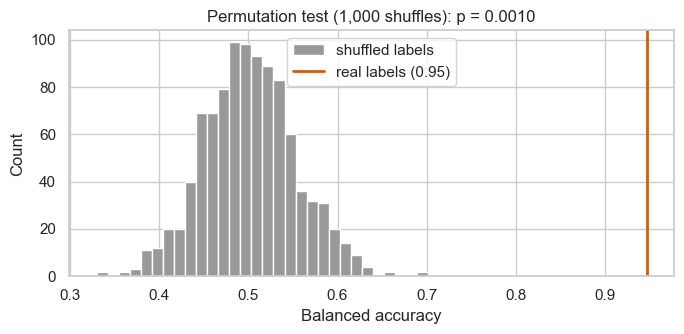

Real model: 0.947 | best shuffled model: 0.702 | p = 0.0010


In [6]:
from src.feature_extraction import vectorize
from src.evaluation import permutation_test

# Correlation features are computed per person, so computing them up front leaks nothing between people
X_corr = vectorize(time_series, kind="correlation")
score, perm_scores, p_perm = permutation_test(X_corr, y, n_permutations=1000)

plt.figure(figsize=(7, 3.5))
plt.hist(perm_scores, bins=30, color="#999999", label="shuffled labels")
plt.axvline(score, c="#D55E00", lw=2, label=f"real labels ({score:.2f})")
plt.xlabel("Balanced accuracy"); plt.ylabel("Count"); plt.legend()
plt.title(f"Permutation test (1,000 shuffles): p = {p_perm:.4f}")
plt.tight_layout(); plt.show()
print(f"Real model: {score:.3f} | best shuffled model: {perm_scores.max():.3f} | p = {p_perm:.4f}")

## 4. Summary of all models

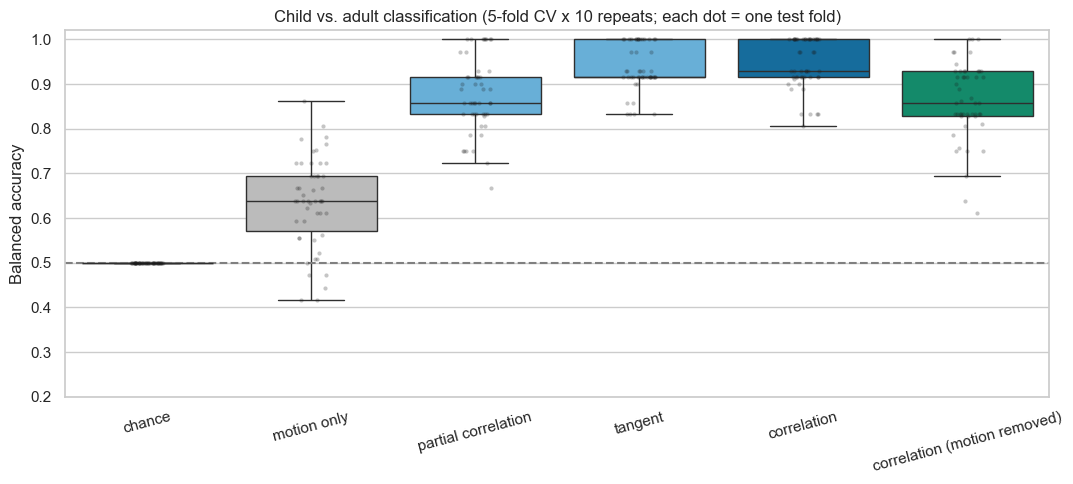

,mean,std,min
chance,0.500,0.000,0.500
motion only,0.635,0.100,0.417
partial correlation,0.875,0.082,0.667
tangent,0.937,0.051,0.833
correlation,0.945,0.055,0.806
correlation (motion removed),0.862,0.085,0.611


In [7]:
plot_order = ["chance", "motion only", "partial correlation", "tangent", "correlation",
              "correlation (motion removed)"]
res_df = pd.concat([pd.DataFrame({"model": k, "balanced_accuracy": scores[k]}) for k in plot_order])
colors = ["#BBBBBB", "#BBBBBB", "#56B4E9", "#56B4E9", "#0072B2", "#009E73"]

plt.figure(figsize=(11, 5))
sns.boxplot(data=res_df, x="model", y="balanced_accuracy", hue="model", palette=colors,
            order=plot_order, showfliers=False)
sns.stripplot(data=res_df, x="model", y="balanced_accuracy", order=plot_order,
              color="k", alpha=0.25, size=3)
plt.axhline(0.5, ls="--", c="gray")
plt.ylim(0.2, 1.02)
plt.xticks(rotation=15)
plt.title("Child vs. adult classification (5-fold CV x 10 repeats; each dot = one test fold)")
plt.ylabel("Balanced accuracy"); plt.xlabel("")
plt.tight_layout(); save("03_classification_accuracy"); plt.show()

summary = pd.DataFrame({k: {"mean": scores[k].mean(), "std": scores[k].std(),
                            "min": scores[k].min()} for k in plot_order}).T.round(3)
summary

**Insights**
- **H1, supported.** Connectivity separates children from adults very well: **correlation 0.945 ± 0.055** balanced accuracy, with tangent close behind (0.937). Partial correlation is lower (0.875), probably because estimating *direct* links from only 168 time points is noisy.
- **H3, supported.** Motion alone reaches only 0.635. After regressing motion out of every connection, accuracy falls to **0.862**, still far above the motion-only model. This is a *conservative* test: since motion and group are correlated, removing motion also removes some genuine age signal.
- **Not luck:** none of the 1,000 shuffled-label models matched the real one (p ≈ 0.001, the smallest value possible with 1,000 shuffles).
- We keep the **correlation** model: it is the most accurate and also the easiest to interpret (its weights are actual region pairs).

## 5. Save results for error analysis (notebook 04)

In [8]:
best = cv_results["correlation"]
np.savez(f"{DATA_DIR}/cv_correlation.npz", prob_adult=best["prob_adult"],
         weights=best["weights"], confusion=best["confusion"])
summary.assign(permutation_p=lambda d: np.where(d.index == "correlation", p_perm, np.nan)) \
       .to_csv(f"{DATA_DIR}/model_summary.csv")
print("Saved.")

Saved.


## Summary

| Model | Balanced accuracy |
|---|---|
| Chance | 0.500 |
| Motion only | 0.635 ± 0.100 |
| Partial correlation | 0.875 ± 0.082 |
| Tangent | 0.937 ± 0.051 |
| **Correlation** | **0.945 ± 0.055** (permutation p ≈ 0.001) |
| Correlation, motion regressed out | 0.862 ± 0.085 |

Full table: [`results/model_evaluation.md`](../results/model_evaluation.md). **Next:** notebook 04 looks at the errors.